# Project 4 — Deep Learning Systems
## Land-use classification of Sentinel-2 satellite images with a CNN (EuroSAT)

**Task type:** image classification with a **Convolutional Neural Network (CNN)**, implemented in PyTorch.

**Question:** given a 64 × 64 px satellite image patch, which of 10 land-use classes does it show (forest, river, highway, crops, …)?

**Controlled experiment:** a baseline CNN *without* dropout vs. the *identical* CNN with dropout (p = 0.5) in the classifier head. Everything else is held fixed. Each configuration is trained with 3 random seeds so that a real effect can be told apart from run-to-run noise.

**Notebook outline**
0. Setup & reproducibility
1. Problem definition and dataset choice
2. Load and inspect the data
3. Preprocessing: stratified split and normalisation
4. Baseline model
5. Training utilities
6. Baseline training
7. Controlled experiment (dropout)
8. Evaluation and comparison
9. Error analysis
10. Notebook summary

## 0. Setup & reproducibility

All hyperparameters live in one config dictionary. The experimental configuration is created from it by changing a single key, and the code below **asserts** that exactly one key differs. Both configurations then go through the same training function, so the "everything else stayed the same" claim is enforced by code rather than by promise.

In [1]:
import os, time, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.datasets import EuroSAT

# Paths
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FIG_DIR, MET_DIR, CKPT_DIR = OUT_DIR / "figures", OUT_DIR / "metrics", OUT_DIR / "checkpoints"
for d in (DATA_DIR, FIG_DIR, MET_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Device: CUDA GPU -> Apple-silicon GPU (MPS) -> CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Python libs: numpy {np.__version__} | pandas {pd.__version__} | torch {torch.__version__} "
      f"| torchvision {torchvision.__version__}")
print(f"Device: {DEVICE}")

def set_seed(seed: int) -> None:
    # Seed every random number generator the experiment touches.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA / MPS generators

# Plot style (colour-blind-safe pair, validated): baseline = blue/solid, dropout = orange/dashed
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.35})
COLORS = {"baseline": "#2a78d6", "dropout": "#eb6834"}
STYLES = {"baseline": "-", "dropout": "--"}
SEQ_CMAP = LinearSegmentedColormap.from_list("blue_seq", ["#fcfcfb", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

def savefig(fig, name):
    # Saved PNGs are reused in the report, which numbers figures itself: drop the notebook's figure title.
    st = fig._suptitle
    if st is not None:
        st.set_visible(False)
    fig.savefig(FIG_DIR / f"{name}.png")
    if st is not None:
        st.set_visible(True)

Python libs: numpy 2.5.5 | pandas 3.1.1 | torch 2.15.0 | torchvision 0.29.2
Device: mps


In [2]:
# ---- Experiment configuration -------------------------------------------------
BASE_CONFIG = {
    "batch_size": 64,
    "lr": 1e-3,
    "optimizer": "Adam",
    "weight_decay": 0.0,
    "epochs": 25,
    "dropout": 0.0,          # <- the only thing the experiment changes
    "augmentation": False,
}
EXP_CONFIG = {**BASE_CONFIG, "dropout": 0.5}
CONFIGS = {"baseline": BASE_CONFIG, "dropout": EXP_CONFIG}

SEEDS = [0, 1, 2]     # training seeds (same 3 seeds for both configurations)
SPLIT_SEED = 42       # data split seed (one fixed split shared by every run)

changed = {k: (BASE_CONFIG[k], EXP_CONFIG[k]) for k in BASE_CONFIG if BASE_CONFIG[k] != EXP_CONFIG[k]}
assert len(changed) == 1, f"Controlled experiment must change exactly one setting, got {changed}"
pd.DataFrame({"baseline": BASE_CONFIG, "dropout (experiment)": EXP_CONFIG})

,baseline,dropout (experiment)
batch_size,64,64
lr,0.001,0.001
optimizer,Adam,Adam
weight_decay,0.0,0.0
epochs,25,25
dropout,0.0,0.5
augmentation,False,False


## 1. Problem definition and dataset choice

**Task:** 10-class, single-label image classification → **CNN**.

**Dataset:** [EuroSAT RGB](https://github.com/phelber/eurosat) (Helber et al., 2019): 27,000 real Sentinel-2 satellite image patches (64 × 64 px, ≈ 640 m × 640 m on the ground) from 34 European countries, labelled into 10 land-use / land-cover classes. Publicly available for research use, not synthetic, and not used in any of my previous capstone projects.

> Helber, P., Bischke, B., Dengel, A., & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 12*(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242

**Why a CNN fits this data:** land-use classes are recognised by *local spatial patterns* (crop-row stripes, road lines, building grids, water texture) that can appear anywhere in the patch. Convolutions share the same small filters across every position (translation equivariance) and stack them to build up larger patterns, which is exactly this structure. A recurrent network or Transformer would have to learn this spatial prior from data, which is less efficient for a dataset of this size.

**Why it matters:** automatic land-use mapping supports agriculture monitoring, urban planning, deforestation tracking and disaster response, where manual labelling of satellite imagery does not scale.

**Access:** downloaded automatically by `torchvision.datasets.EuroSAT` (≈ 90 MB). Full instructions and a manual fallback are in `data/README.md`.

## 2. Load and inspect the data

To keep training fast, all 27,000 images are decoded once into a single `uint8` array (≈ 330 MB) and cached to `data/eurosat_rgb_uint8.npz`. On later runs the cache is loaded instead and checked against the file list.

In [3]:
raw = EuroSAT(root=str(DATA_DIR), download=True)     # downloads on first run only
CLASSES = raw.classes
NUM_CLASSES = len(CLASSES)
paths = [os.path.relpath(p, DATA_DIR) for p, _ in raw.samples]
labels = np.array([y for _, y in raw.samples], dtype=np.int64)

CACHE = DATA_DIR / "eurosat_rgb_uint8.npz"
if CACHE.exists():
    cached = np.load(CACHE, allow_pickle=False)
    X, cached_labels = cached["X"], cached["y"]
    assert np.array_equal(cached_labels, labels), "Cache does not match the dataset - delete it and re-run."
else:
    t0 = time.time()
    X = np.stack([np.asarray(raw.loader(p).convert("RGB")) for p, _ in raw.samples])
    np.savez(CACHE, X=X, y=labels)
    print(f"Decoded {len(X):,} images in {time.time() - t0:.1f}s")

df = pd.DataFrame({"path": paths, "label": labels, "class": [CLASSES[y] for y in labels]})
print(f"Images: {len(X):,} | array shape (N, H, W, C) = {X.shape} | dtype = {X.dtype} "
      f"| pixel range = [{X.min()}, {X.max()}]")
print(f"Classes ({NUM_CLASSES}): {CLASSES}")
df.head()

Images: 27,000 | array shape (N, H, W, C) = (27000, 64, 64, 3) | dtype = uint8 | pixel range = [0, 255]
Classes (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


,path,label,class
0,eurosat/2750/AnnualCrop/AnnualCrop_1.jpg,0,AnnualCrop
1,eurosat/2750/AnnualCrop/AnnualCrop_10.jpg,0,AnnualCrop
2,eurosat/2750/AnnualCrop/AnnualCrop_100.jpg,0,AnnualCrop
3,eurosat/2750/AnnualCrop/AnnualCrop_1000.jpg,0,AnnualCrop
4,eurosat/2750/AnnualCrop/AnnualCrop_1001.jpg,0,AnnualCrop


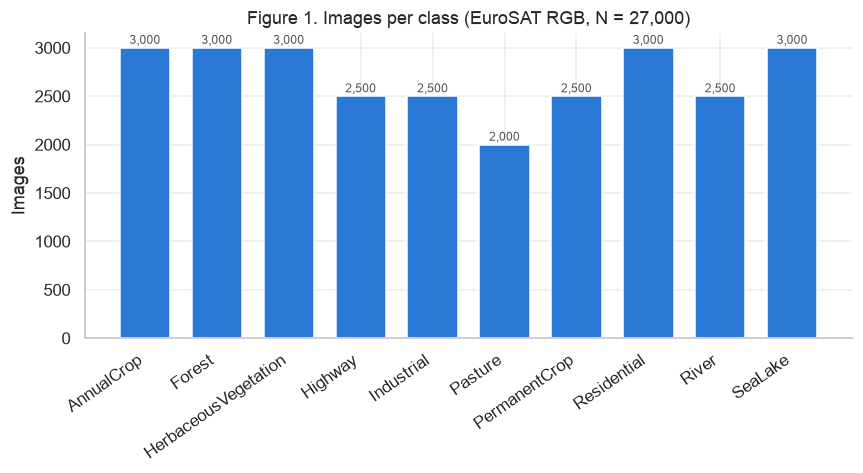

Smallest / largest class: 2,000 / 3,000 (imbalance ratio 1.50)


In [4]:
counts = df["class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(CLASSES, counts.values, color=COLORS["baseline"], width=0.7)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v:,}", ha="center", fontsize=8, color="#52514e")
ax.set_ylabel("Images")
ax.set_title("Figure 1. Images per class (EuroSAT RGB, N = 27,000)")
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
savefig(fig, "fig1_class_counts")
plt.show()
print(f"Smallest / largest class: {counts.min():,} / {counts.max():,} "
      f"(imbalance ratio {counts.max() / counts.min():.2f})")

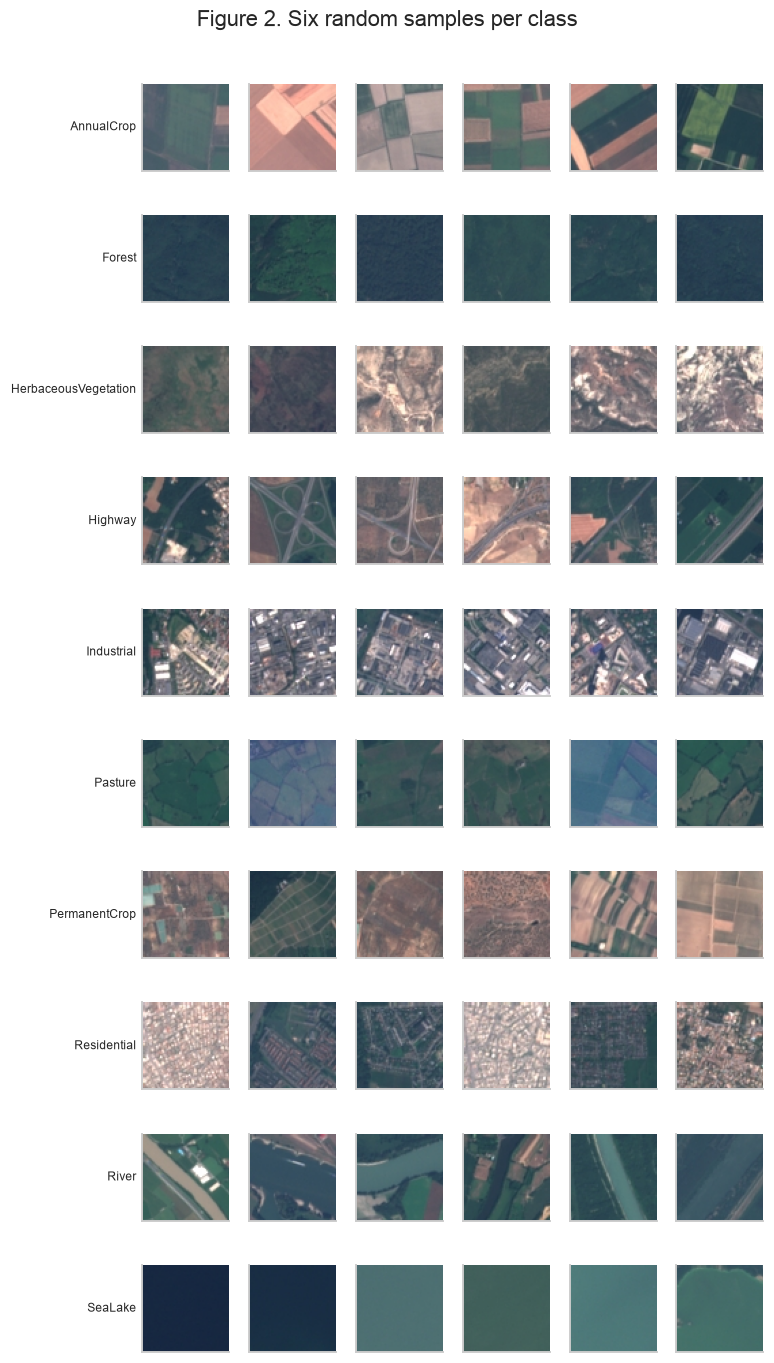

In [5]:
# Representative samples: 6 random images per class
rng = np.random.default_rng(0)
n_per = 6
fig, axes = plt.subplots(NUM_CLASSES, n_per, figsize=(n_per * 1.2, NUM_CLASSES * 1.25))
for c, name in enumerate(CLASSES):
    idx = rng.choice(np.where(labels == c)[0], n_per, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X[i]); ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
fig.suptitle("Figure 2. Six random samples per class", y=1.0)
plt.tight_layout()
savefig(fig, "fig2_samples")
plt.show()

In [6]:
# Data-quality checks
shapes = {img.shape for img in X[:: 500]}
dup_mask = pd.Series([hash(img.tobytes()) for img in X]).duplicated(keep=False).values
per_class_brightness = pd.Series(X.reshape(len(X), -1).mean(1)).groupby(labels).mean()
per_class_brightness.index = CLASSES

print(f"Distinct image shapes (sampled): {shapes}")
print(f"Missing labels: {int(pd.isna(df['label']).sum())}")
print(f"Images whose exact pixels appear more than once: {int(dup_mask.sum())}")
print("\nMean pixel intensity per class (0-255):")
print(per_class_brightness.round(1).to_string())

Distinct image shapes (sampled): {(64, 64, 3)}
Missing labels: 0
Images whose exact pixels appear more than once: 0

Mean pixel intensity per class (0-255):
AnnualCrop              122.3
Forest                   59.9
HerbaceousVegetation    100.3
Highway                  96.0
Industrial              127.7
Pasture                  81.5
PermanentCrop           117.4
Residential             105.6
River                    83.5
SeaLake                  70.0


**Observations / preprocessing considerations**
- Every image is already 64 × 64 × 3 (`uint8`, 0–255), so no resizing or cropping is needed. Labels come from the folder structure and none are missing.
- Classes are mildly imbalanced (2,000 to 3,000 images). This is why **macro-F1** (which weights every class equally) is reported next to accuracy, and why the split is **stratified**.
- Average brightness differs strongly by class (e.g. dark `SeaLake` / `Forest` vs. bright `Industrial` / `AnnualCrop`). A model could partly lean on colour/brightness shortcuts instead of texture. This was not tested separately.
- Only the RGB bands are used. The original Sentinel-2 product has 13 spectral bands (including near-infrared, which is very informative for vegetation). This is a limitation, discussed in the report.

## 3. Preprocessing: stratified split and normalisation

- **Split:** 70 % train / 15 % validation / 15 % test, stratified by class with a fixed seed and saved to `data/splits.csv`. Validation drives checkpoint selection, and the test split is never used for training, checkpoint selection or configuration choices.
- **Normalisation:** pixels are scaled to [0, 1] and then standardised per channel using the mean/std of the **training split only**, so no information from validation/test leaks into preprocessing.
- **No data augmentation** in either configuration. Augmentation is itself a regulariser, so adding it would confound the dropout comparison.

In [7]:
split_rng = np.random.default_rng(SPLIT_SEED)
split = np.empty(len(labels), dtype=object)
for c in range(NUM_CLASSES):
    idx = np.where(labels == c)[0]
    split_rng.shuffle(idx)
    n_tr, n_va = int(round(0.70 * len(idx))), int(round(0.15 * len(idx)))
    split[idx[:n_tr]] = "train"
    split[idx[n_tr:n_tr + n_va]] = "val"
    split[idx[n_tr + n_va:]] = "test"
df["split"] = split
df.to_csv(DATA_DIR / "splits.csv", index_label="index")

tr_idx, va_idx, te_idx = (np.where(split == s)[0] for s in ("train", "val", "test"))
print(f"train {len(tr_idx):,} | val {len(va_idx):,} | test {len(te_idx):,}")
pd.crosstab(df["class"], df["split"]).reindex(CLASSES)[["train", "val", "test"]]

train 18,900 | val 4,050 | test 4,050


split,train,val,test
class,,,
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375


In [8]:
# Per-channel mean / std from the TRAINING split only
train_imgs = X[tr_idx]
CH_MEAN = np.array([(train_imgs[..., ch] / 255.0).mean() for ch in range(3)], dtype=np.float32)
CH_STD = np.array([(train_imgs[..., ch] / 255.0).std() for ch in range(3)], dtype=np.float32)
del train_imgs
print("train mean (R, G, B):", CH_MEAN.round(4), "| train std:", CH_STD.round(4))

# Keep images as uint8 on the device (small), normalise each batch on the fly
def to_device_tensor(idx):
    x = torch.from_numpy(X[idx]).permute(0, 3, 1, 2).contiguous().to(DEVICE)   # N, 3, 64, 64 uint8
    y = torch.from_numpy(labels[idx]).to(DEVICE)
    return x, y

Xtr, ytr = to_device_tensor(tr_idx)
Xva, yva = to_device_tensor(va_idx)
Xte, yte = to_device_tensor(te_idx)

_mean = torch.tensor(CH_MEAN, device=DEVICE).view(1, 3, 1, 1)
_std = torch.tensor(CH_STD, device=DEVICE).view(1, 3, 1, 1)

def normalize(x_uint8):
    return (x_uint8.float() / 255.0 - _mean) / _std

xb = normalize(Xtr[::300])   # every 300th training image (spans all classes)
print(f"Model input batch: shape {tuple(xb.shape)}, dtype {xb.dtype}, "
      f"mean {xb.mean().item():.3f}, std {xb.std().item():.3f}")

train mean (R, G, B): [0.3445 0.3803 0.4079] | train std: [0.2026 0.1367 0.1155]


Model input batch: shape (63, 3, 64, 64), dtype torch.float32, mean -0.076, std 0.949


## 4. Baseline model

```
Input 3×64×64
Block 1: Conv3×3(32)  → BN → ReLU → Conv3×3(32)  → BN → ReLU → MaxPool2   → 32×32×32
Block 2: Conv3×3(64)  → BN → ReLU → Conv3×3(64)  → BN → ReLU → MaxPool2   → 64×16×16
Block 3: Conv3×3(128) → BN → ReLU → Conv3×3(128) → BN → ReLU → MaxPool2   → 128×8×8
Head:    GlobalAvgPool → Linear(128→256) → ReLU → Dropout(p) → Linear(256→10 logits)
```

**Key design choices**
- **Stacked 3×3 convolutions** (VGG-style): two 3×3 layers see a 5×5 region with fewer parameters and an extra non-linearity compared with one 5×5 layer. Channel width doubles (32→64→128) each time the spatial size halves, so the computation per block stays balanced.
- **Batch normalisation** after each convolution stabilises activations, so a plain Adam schedule converges within 25 epochs. Conv layers therefore have no bias (BN's shift replaces it).
- **ReLU** activations: cheap and they avoid the vanishing gradients of saturating activations.
- **Max-pooling** halves the resolution, adding some tolerance to small shifts and enlarging the receptive field.
- **Global average pooling** instead of flattening 128×8×8 = 8,192 features: about 59× fewer parameters in the head (35,594 vs. about 2.1 million) and a summary of "how much of each pattern is present", which suits texture-like classes.
- **Output:** 10 raw logits. `CrossEntropyLoss` applies log-softmax internally, the standard loss for single-label multi-class classification.
- **Dropout(p)** is a parameter of the class. The baseline uses `p = 0.0`, where `nn.Dropout` is an exact identity, so both configurations share literally the same architecture code.

In [9]:
def conv_block(c_in: int, c_out: int) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class EuroSATCNN(nn.Module):
    def __init__(self, num_classes: int = 10, dropout: float = 0.0):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.pool(self.features(x)))


model = EuroSATCNN(NUM_CLASSES, dropout=BASE_CONFIG["dropout"])
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {n_params:,}")
with torch.no_grad():
    print("Output shape for a batch of 2:", tuple(model(torch.zeros(2, 3, 64, 64)).shape))

EuroSATCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, t

## 5. Training utilities

- **Loss:** cross-entropy. **Optimizer:** Adam (lr = 1e-3), a robust default that needs little tuning, which suits a baseline.
- **Batch order** comes from a separate, seeded CPU generator, so for a given seed the baseline and dropout runs see **the same mini-batches in the same order** and start from **the same initial weights** (dropout has no parameters). The only difference between paired runs is the dropout mask.
- **Checkpoint rule (same for both configurations):** train for all 25 epochs and keep the weights from the epoch with the **lowest validation loss**. Training is deliberately not stopped early, so the full curves show whether and when overfitting starts.
- Training-set loss/accuracy are logged *during* training (dropout active for the experiment). To compare generalisation fairly, the train accuracy of the selected checkpoint is re-measured later in eval mode.

In [10]:
def batches(X_u8, y, batch_size, shuffle=False, generator=None):
    n = len(y)
    order = torch.randperm(n, generator=generator) if shuffle else torch.arange(n)
    order = order.to(X_u8.device)
    for i in range(0, n, batch_size):
        idx = order[i:i + batch_size]
        yield normalize(X_u8[idx]), y[idx]


def run_epoch(model, X_u8, y, batch_size, optimizer=None, generator=None):
    # One pass over the data. Trains if an optimizer is given, otherwise evaluates.
    training = optimizer is not None
    model.train(training)
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    with torch.set_grad_enabled(training):
        for xb, yb in batches(X_u8, y, batch_size, shuffle=training, generator=generator):
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            loss_sum += loss.detach() * len(yb)
            correct += (logits.argmax(1) == yb).sum()
    n = len(y)
    return loss_sum.item() / n, correct.item() / n


def run_experiment(name, cfg, seed, verbose=True):
    set_seed(seed)
    model = EuroSATCNN(NUM_CLASSES, dropout=cfg["dropout"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    batch_gen = torch.Generator().manual_seed(seed)

    history, best = [], {"val_loss": float("inf")}
    t_start = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, Xtr, ytr, cfg["batch_size"], optimizer, batch_gen)
        va_loss, va_acc = run_epoch(model, Xva, yva, 512)
        history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "seconds": time.time() - t0})
        if va_loss < best["val_loss"]:
            best = {"val_loss": va_loss, "val_acc": va_acc, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"  [{name} seed {seed}] epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
                  f"| val loss {va_loss:.4f} acc {va_acc:.4f} | {history[-1]['seconds']:.1f}s")

    hist = pd.DataFrame(history).assign(config=name, seed=seed)
    hist.to_csv(MET_DIR / f"history_{name}_seed{seed}.csv", index=False)
    torch.save(best["state"], CKPT_DIR / f"{name}_seed{seed}.pt")
    model.load_state_dict(best["state"])
    print(f"  -> best epoch {best['epoch']} (val loss {best['val_loss']:.4f}, val acc {best['val_acc']:.4f}); "
          f"total {time.time() - t_start:.0f}s")
    return model, hist, best["epoch"]


@torch.no_grad()
def predict_proba(model, X_u8, batch_size=512):
    model.eval()
    out = [F.softmax(model(normalize(X_u8[i:i + batch_size])), dim=1).cpu()
           for i in range(0, len(X_u8), batch_size)]
    return torch.cat(out).numpy()

In [11]:
# Metrics implemented in NumPy (no extra libraries needed)
def confusion_matrix(y_true, y_pred, k=NUM_CLASSES):
    cm = np.zeros((k, k), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm


def classification_metrics(y_true, y_pred, k=NUM_CLASSES):
    cm = confusion_matrix(y_true, y_pred, k)
    tp = np.diag(cm).astype(float)
    precision = tp / np.maximum(cm.sum(axis=0), 1)
    recall = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = np.where(precision + recall > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0.0)
    return {"accuracy": tp.sum() / cm.sum(), "macro_f1": f1.mean(),
            "precision": precision, "recall": recall, "f1": f1, "cm": cm}


# Sanity check on a toy example: 3 classes, one mistake (true 2 predicted as 1)
_m = classification_metrics(np.array([0, 0, 1, 2, 2]), np.array([0, 0, 1, 1, 2]), k=3)
assert np.isclose(_m["accuracy"], 0.8) and np.allclose(_m["recall"], [1, 1, 0.5]) and np.allclose(_m["precision"], [1, 0.5, 1])
print("metric functions OK:", {k: np.round(v, 3).tolist() for k, v in _m.items() if k in ("accuracy", "macro_f1", "f1")})

metric functions OK: {'accuracy': 0.8, 'macro_f1': 0.778, 'f1': [1.0, 0.667, 0.667]}


## 6. Baseline training (3 seeds)

In [12]:
models, histories, best_epochs = {}, [], {}
for seed in SEEDS:
    m, h, be = run_experiment("baseline", BASE_CONFIG, seed)
    models[("baseline", seed)], best_epochs[("baseline", seed)] = m, be
    histories.append(h)

  [baseline seed 0] epoch  1 | train loss 0.8038 acc 0.7199 | val loss 0.5312 acc 0.8175 | 13.0s


  [baseline seed 0] epoch  5 | train loss 0.2728 acc 0.9062 | val loss 0.3338 acc 0.8798 | 12.7s


  [baseline seed 0] epoch 10 | train loss 0.1695 acc 0.9414 | val loss 0.2327 acc 0.9249 | 12.7s


  [baseline seed 0] epoch 15 | train loss 0.1251 acc 0.9550 | val loss 0.1542 acc 0.9514 | 12.7s


  [baseline seed 0] epoch 20 | train loss 0.0996 acc 0.9640 | val loss 0.1133 acc 0.9605 | 12.7s


  [baseline seed 0] epoch 25 | train loss 0.0748 acc 0.9743 | val loss 0.1238 acc 0.9622 | 12.7s
  -> best epoch 20 (val loss 0.1133, val acc 0.9605); total 318s


... (8 outputs left out)

  [baseline seed 2] epoch 10 | train loss 0.1687 acc 0.9410 | val loss 0.2075 acc 0.9267 | 12.6s


  [baseline seed 2] epoch 15 | train loss 0.1277 acc 0.9566 | val loss 0.2519 acc 0.9220 | 12.6s


  [baseline seed 2] epoch 20 | train loss 0.0985 acc 0.9650 | val loss 0.1543 acc 0.9469 | 12.6s


  [baseline seed 2] epoch 25 | train loss 0.0733 acc 0.9741 | val loss 0.1190 acc 0.9585 | 12.6s
  -> best epoch 24 (val loss 0.1144, val acc 0.9627); total 316s


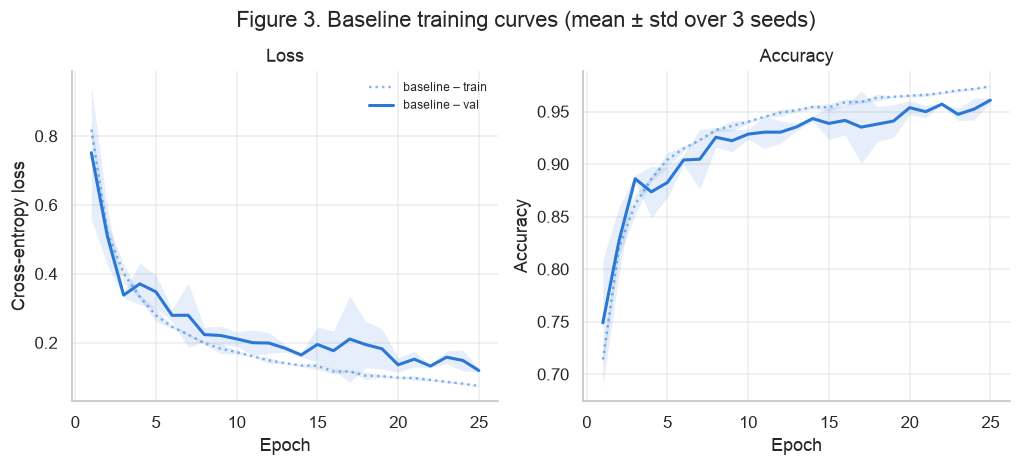

Baseline, mean over seeds: lowest val loss 0.1189 at epoch 25, final-epoch val loss 0.1189
Final epoch: train acc 0.9740 vs val acc 0.9608 (gap 0.0132)


In [13]:
def plot_curves(hist_df, configs, title, fname):
    # Mean ± std across seeds for loss and accuracy (train and validation)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
    for metric, ax in zip(["loss", "acc"], axes):
        for cfg in configs:
            g = hist_df[hist_df.config == cfg].groupby("epoch")
            for split_name, alpha, lw in (("train", 0.55, 1.6), ("val", 1.0, 2.0)):
                mean, std = g[f"{split_name}_{metric}"].mean(), g[f"{split_name}_{metric}"].std()
                ax.plot(mean.index, mean.values, STYLES[cfg] if split_name == "val" else ":",
                        color=COLORS[cfg], alpha=alpha, lw=lw, label=f"{cfg} – {split_name}")
                ax.fill_between(mean.index, mean - std, mean + std, color=COLORS[cfg], alpha=0.12, lw=0)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Cross-entropy loss" if metric == "loss" else "Accuracy")
        ax.set_title("Loss" if metric == "loss" else "Accuracy")
    axes[0].legend(fontsize=8, frameon=False)
    fig.suptitle(title, y=1.02)
    savefig(fig, fname)
    plt.show()

hist_all = pd.concat(histories, ignore_index=True)
plot_curves(hist_all, ["baseline"], "Figure 3. Baseline training curves (mean ± std over 3 seeds)", "fig3_baseline_curves")

g = hist_all.groupby("epoch")[["train_loss", "val_loss", "train_acc", "val_acc"]].mean()
print(f"Baseline, mean over seeds: lowest val loss {g.val_loss.min():.4f} at epoch {g.val_loss.idxmin()}, "
      f"final-epoch val loss {g.val_loss.iloc[-1]:.4f}")
print(f"Final epoch: train acc {g.train_acc.iloc[-1]:.4f} vs val acc {g.val_acc.iloc[-1]:.4f} "
      f"(gap {g.train_acc.iloc[-1] - g.val_acc.iloc[-1]:.4f})")

**Reading the baseline curves (motivation for the experiment).** Training and validation loss fall together for most of the run (Figure 3). By the last epoch the baseline fits the training data slightly better than the validation data (mean train accuracy 97.4 % vs. validation 96.1 %), and validation loss is noticeably noisier than training loss (for example seed 2 jumps from 0.21 at epoch 10 to 0.25 at epoch 15 before recovering). However, the mean validation loss is still at its lowest at epoch 25, so the baseline shows a **small, stable generalisation gap rather than classic overfitting** where validation loss turns upward. This is a weaker version of the pattern I expected when planning. The dropout comparison was planned in advance. My plan also called for checking these curves before committing to it, with a learning-rate comparison as fallback if there was no overfitting. In practice both configurations were run together, and dropout was kept after the results were already visible, so this was not a blind decision. I treat the experiment as a test of whether dropout still adds anything to a model that batch normalisation and global average pooling already regularise.

## 7. Controlled experiment: adding dropout

| | Baseline | Experiment |
|---|---|---|
| **Changed** | Dropout p = 0.0 (identity) | **Dropout p = 0.5** before the final linear layer |
| Data split, normalisation, no augmentation | same | same |
| Architecture (conv blocks, BN, GAP, 256-unit head) | same | same |
| Initial weights and mini-batch order (per seed) | same | same |
| Optimizer, learning rate, batch size, epochs | Adam, 1e-3, 64, 25 | Adam, 1e-3, 64, 25 |
| Seeds, checkpoint rule, hardware | 0/1/2, lowest val loss, same device | same |

**Why this change.** Dropout randomly zeroes hidden units during training, which stops units from co-adapting and acts like training an ensemble of thinned networks (Srivastava et al., 2014). It targets the train–validation gap seen in the baseline curves and acts on the only fully connected part of the network, the 256-unit head, so the experiment tests a concrete hypothesis instead of an arbitrary tweak. It is also a single scalar, so "exactly one change" is unambiguous.

> Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html

**Hypothesis (written before the full training runs):** dropout will narrow the gap between training and validation performance and slow the rise in validation loss, at the cost of slower training convergence. Its effect on test accuracy may be small, because batch normalisation and global average pooling already regularise the baseline.

In [14]:
print("Changed setting(s):", changed)
for seed in SEEDS:
    m, h, be = run_experiment("dropout", EXP_CONFIG, seed)
    models[("dropout", seed)], best_epochs[("dropout", seed)] = m, be
    histories.append(h)
hist_all = pd.concat(histories, ignore_index=True)
hist_all.to_csv(MET_DIR / "history_all.csv", index=False)

Changed setting(s): {'dropout': (0.0, 0.5)}


  [dropout seed 0] epoch  1 | train loss 0.8698 acc 0.7003 | val loss 0.6155 acc 0.7672 | 12.6s


  [dropout seed 0] epoch  5 | train loss 0.3185 acc 0.8965 | val loss 0.3192 acc 0.8847 | 12.6s


  [dropout seed 0] epoch 10 | train loss 0.1897 acc 0.9383 | val loss 0.1698 acc 0.9432 | 12.6s


  [dropout seed 0] epoch 15 | train loss 0.1436 acc 0.9513 | val loss 0.1490 acc 0.9521 | 12.6s


  [dropout seed 0] epoch 20 | train loss 0.1117 acc 0.9608 | val loss 0.1300 acc 0.9558 | 12.6s


... (9 outputs left out)

  [dropout seed 2] epoch 10 | train loss 0.1859 acc 0.9361 | val loss 0.1700 acc 0.9417 | 12.6s


  [dropout seed 2] epoch 15 | train loss 0.1520 acc 0.9493 | val loss 0.1982 acc 0.9314 | 12.6s


  [dropout seed 2] epoch 20 | train loss 0.1143 acc 0.9618 | val loss 0.1310 acc 0.9546 | 12.6s


  [dropout seed 2] epoch 25 | train loss 0.0969 acc 0.9680 | val loss 0.1392 acc 0.9575 | 12.6s
  -> best epoch 22 (val loss 0.1220, val acc 0.9607); total 314s


## 8. Evaluation and comparison

Every run is evaluated on the held-out **test split** (4,050 images) using its best-validation checkpoint. Reported metrics:
- **Accuracy** and **macro-F1** (unweighted mean of the per-class F1, robust to the mild class imbalance).
- **Generalisation gap** = train accuracy (eval mode, same checkpoint) − test accuracy.
- **Overfitting indicator** = rise in validation loss from its minimum to the last epoch.
- Mean ± standard deviation over 3 seeds, plus the **paired per-seed difference** (same seed = same initialisation and batch order).

In [15]:
rows, probs = [], {}
for (cfg, seed), m in models.items():
    p = predict_proba(m, Xte)
    probs[(cfg, seed)] = p
    y_pred = p.argmax(1)
    met = classification_metrics(labels[te_idx], y_pred)
    train_acc_eval = (predict_proba(m, Xtr).argmax(1) == labels[tr_idx]).mean()
    h = hist_all[(hist_all.config == cfg) & (hist_all.seed == seed)]
    rows.append({"config": cfg, "seed": seed, "best_epoch": best_epochs[(cfg, seed)],
                 "test_acc": met["accuracy"], "test_macro_f1": met["macro_f1"],
                 "train_acc_eval": train_acc_eval, "gen_gap": train_acc_eval - met["accuracy"],
                 "min_val_loss": h.val_loss.min(), "final_val_loss": h.val_loss.iloc[-1],
                 "val_loss_rise": h.val_loss.iloc[-1] - h.val_loss.min(),
                 "sec_per_epoch": h.seconds.mean()})
results = pd.DataFrame(rows)
results.to_csv(MET_DIR / "results_per_run.csv", index=False)
results.round(4)

,config,seed,best_epoch,test_acc,test_macro_f1,train_acc_eval,gen_gap,min_val_loss,final_val_loss,val_loss_rise,sec_per_epoch
0,baseline,0,20,0.9600,0.9590,0.9825,0.0225,0.1133,0.1238,0.0105,12.7304
1,baseline,1,25,0.9617,0.9604,0.9821,0.0203,0.1140,0.1140,0.0000,12.6819
2,baseline,2,24,0.9694,0.9686,0.9789,0.0096,0.1144,0.1190,0.0046,12.6231
3,dropout,0,23,0.9637,0.9629,0.9771,0.0134,0.1105,0.1236,0.0131,12.5858
4,dropout,1,20,0.9632,0.9621,0.9760,0.0128,0.1158,0.1341,0.0182,12.6072
5,dropout,2,22,0.9585,0.9574,0.9754,0.0169,0.1220,0.1392,0.0172,12.5735


In [16]:
cols = ["test_acc", "test_macro_f1", "gen_gap", "best_epoch", "min_val_loss", "val_loss_rise", "sec_per_epoch"]
summary = results.groupby("config")[cols].agg(["mean", "std"]).reindex(["baseline", "dropout"])
summary.to_csv(MET_DIR / "results_summary.csv")

pretty = pd.DataFrame({c: summary[c]["mean"].map("{:.4f}".format) + " ± " + summary[c]["std"].map("{:.4f}".format)
                       for c in cols})
display(pretty)

paired = (results.pivot(index="seed", columns="config", values=["test_acc", "test_macro_f1", "gen_gap", "val_loss_rise"])
          .swaplevel(axis=1))
diff = pd.DataFrame({m: paired[("dropout", m)] - paired[("baseline", m)]
                     for m in ["test_acc", "test_macro_f1", "gen_gap", "val_loss_rise"]})
print("Paired difference per seed (dropout − baseline):")
display(diff.round(4))
print("Mean paired difference:", diff.mean().round(4).to_dict())
print("Seeds where dropout has higher test accuracy:", int((diff.test_acc > 0).sum()), "of", len(diff))

summary_json = {
    "per_config": {cfg: {c: {"mean": float(summary.loc[cfg, (c, "mean")]), "std": float(summary.loc[cfg, (c, "std")])}
                         for c in cols} for cfg in ["baseline", "dropout"]},
    "paired_diff_mean": {k: float(v) for k, v in diff.mean().items()},
}
_ = (MET_DIR / "results_summary.json").write_text(json.dumps(summary_json, indent=2))

,test_acc,test_macro_f1,gen_gap,best_epoch,min_val_loss,val_loss_rise,sec_per_epoch
config,,,,,,,
baseline,0.9637 ± 0.0050,0.9627 ± 0.0052,0.0175 ± 0.0069,23.0000 ± 2.6458,0.1139 ± 0.0005,0.0050 ± 0.0052,12.6785 ± 0.0537
dropout,0.9618 ± 0.0029,0.9608 ± 0.0029,0.0144 ± 0.0022,21.6667 ± 1.5275,0.1161 ± 0.0057,0.0162 ± 0.0027,12.5889 ± 0.0171


Paired difference per seed (dropout − baseline):


,test_acc,test_macro_f1,gen_gap,val_loss_rise
seed,,,,
0,0.0037,0.0039,-0.0091,0.0026
1,0.0015,0.0017,-0.0075,0.0182
2,-0.0109,-0.0112,0.0074,0.0126


Mean paired difference: {'test_acc': -0.0019, 'test_macro_f1': -0.0019, 'gen_gap': -0.0031, 'val_loss_rise': 0.0112}
Seeds where dropout has higher test accuracy: 2 of 3


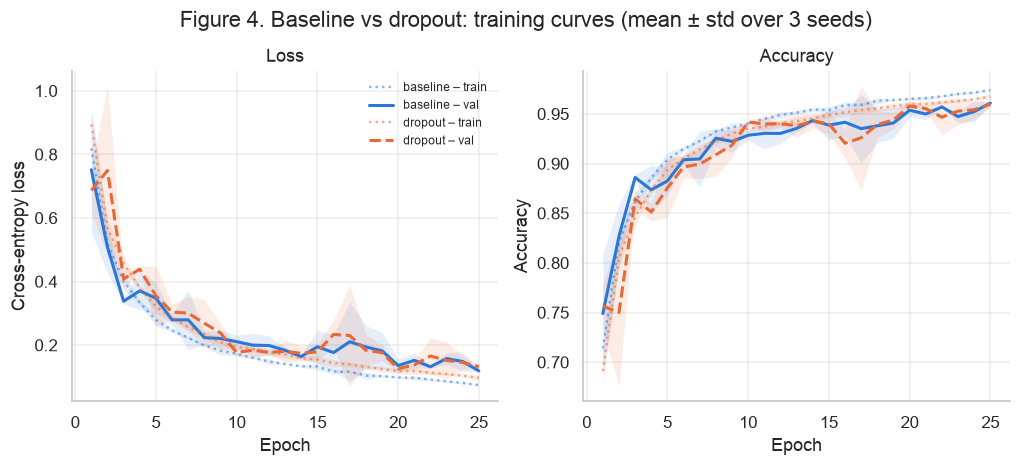

In [17]:
plot_curves(hist_all, ["baseline", "dropout"],
            "Figure 4. Baseline vs dropout: training curves (mean ± std over 3 seeds)", "fig4_comparison_curves")

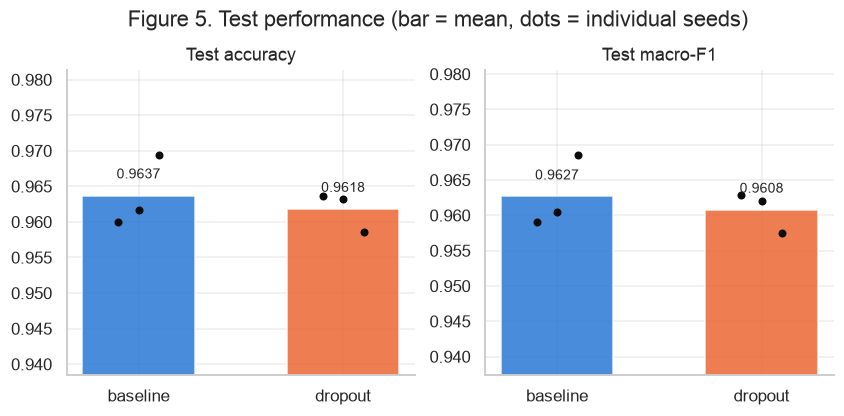

In [18]:
# Test metrics per seed (dots) and their mean (bar)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, metric, label in zip(axes, ["test_acc", "test_macro_f1"], ["Test accuracy", "Test macro-F1"]):
    for i, cfg in enumerate(["baseline", "dropout"]):
        vals = results.loc[results.config == cfg, metric].values
        ax.bar(i, vals.mean(), color=COLORS[cfg], width=0.55, alpha=0.85)
        ax.scatter(np.full(len(vals), i) + np.array([-0.1, 0, 0.1]), vals, color="#0b0b0b", s=18, zorder=3)
        ax.text(i, vals.mean() + 0.002, f"{vals.mean():.4f}", ha="center", va="bottom", fontsize=9)
    lo = results[metric].min()
    ax.set_ylim(lo - 0.02, min(1.0, results[metric].max() + 0.012))
    ax.set_xticks([0, 1], ["baseline", "dropout"])
    ax.set_title(label)
fig.suptitle("Figure 5. Test performance (bar = mean, dots = individual seeds)", y=1.03)
savefig(fig, "fig5_test_metrics")
plt.show()

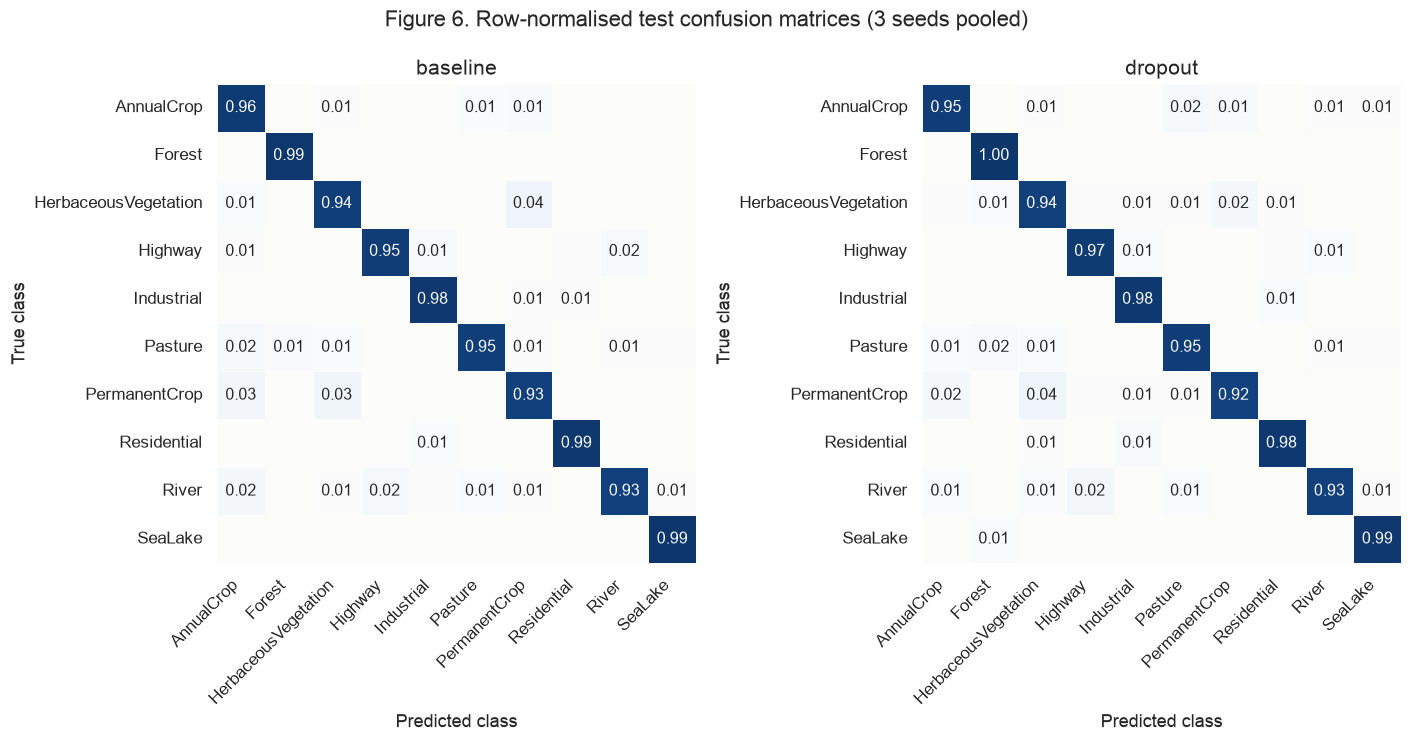

In [19]:
# Confusion matrices, summed over the 3 seeds and row-normalised (rows = true class -> recall on the diagonal)
cms = {cfg: sum(classification_metrics(labels[te_idx], probs[(cfg, s)].argmax(1))["cm"] for s in SEEDS)
       for cfg in ["baseline", "dropout"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
for ax, cfg in zip(axes, ["baseline", "dropout"]):
    cm_norm = cms[cfg] / cms[cfg].sum(axis=1, keepdims=True)
    labels_txt = np.where(cm_norm >= 0.005, np.char.mod("%.2f", cm_norm), "")   # hide 0.00 cells to cut clutter
    sns.heatmap(cm_norm, annot=labels_txt, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"fontsize": 10.5}, linewidths=0.5,
                linecolor="#fcfcfb", square=True)
    ax.set_xlabel("Predicted class", fontsize=12); ax.set_ylabel("True class", fontsize=12)
    ax.set_title(f"{cfg}", fontsize=14)
    ax.tick_params(axis="both", labelsize=11)
    ax.tick_params(axis="x", rotation=45); plt.setp(ax.get_xticklabels(), ha="right")
fig.suptitle("Figure 6. Row-normalised test confusion matrices (3 seeds pooled)", y=1.0)
plt.tight_layout()
savefig(fig, "fig6_confusion_matrices")
plt.show()

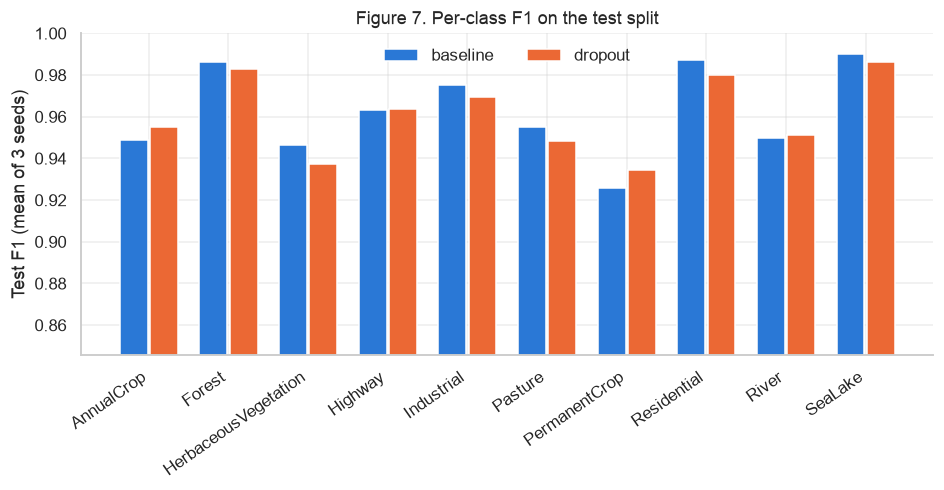

config,baseline,dropout,diff
class,,,
PermanentCrop,0.9256,0.9342,0.0087
HerbaceousVegetation,0.9462,0.9371,-0.0091
AnnualCrop,0.9487,0.9550,0.0062
River,0.9496,0.9511,0.0015
Pasture,0.9551,0.9485,-0.0066
Highway,0.9630,0.9637,0.0007
Industrial,0.9754,0.9692,-0.0061
Forest,0.9860,0.9829,-0.0031
Residential,0.9870,0.9799,-0.0071


In [20]:
# Per-class F1 (mean over seeds)
per_class = []
for (cfg, seed), p in probs.items():
    met = classification_metrics(labels[te_idx], p.argmax(1))
    for c, name in enumerate(CLASSES):
        per_class.append({"config": cfg, "seed": seed, "class": name,
                          "precision": met["precision"][c], "recall": met["recall"][c], "f1": met["f1"][c]})
per_class = pd.DataFrame(per_class)
per_class.to_csv(MET_DIR / "per_class_metrics.csv", index=False)
pc = per_class.groupby(["class", "config"])["f1"].mean().unstack().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(NUM_CLASSES); w = 0.38
for i, cfg in enumerate(["baseline", "dropout"]):
    ax.bar(x + (i - 0.5) * w, pc[cfg].values, w - 0.03, color=COLORS[cfg], label=cfg)
ax.set_xticks(x, CLASSES, rotation=35, ha="right")
ax.set_ylim(max(0, pc.values.min() - 0.08), 1.0)
ax.set_ylabel("Test F1 (mean of 3 seeds)")
ax.legend(frameon=False, ncol=2)
ax.set_title("Figure 7. Per-class F1 on the test split")
savefig(fig, "fig7_per_class_f1")
plt.show()
display(pc.assign(diff=pc["dropout"] - pc["baseline"]).sort_values("baseline").round(4))

## 9. Error analysis

Error cases are examined for the **seed-0** model of each configuration. Three views:
1. which class pairs are confused most often,
2. a gallery of misclassified test images,
3. how confident the model is when it is wrong (over-confidence is a deployment risk).

In [21]:
def top_confusions(cm, n=6):
    off = cm.copy(); np.fill_diagonal(off, 0)
    flat = np.argsort(off, axis=None)[::-1][:n]
    return pd.DataFrame([{"true": CLASSES[i], "predicted": CLASSES[j], "count (3 seeds)": int(off[i, j]),
                          "% of true class": 100 * off[i, j] / cm[i].sum()}
                         for i, j in zip(*np.unravel_index(flat, off.shape))]).round(2)

for cfg in ["baseline", "dropout"]:
    print(f"Most frequent confusions — {cfg}")
    display(top_confusions(cms[cfg]))

Most frequent confusions — baseline


,true,predicted,count (3 seeds),% of true class
0,HerbaceousVegetation,PermanentCrop,48,3.56
1,PermanentCrop,HerbaceousVegetation,36,3.20
2,PermanentCrop,AnnualCrop,35,3.11
3,River,AnnualCrop,23,2.04
4,River,Highway,21,1.87
5,AnnualCrop,PermanentCrop,18,1.33


Most frequent confusions — dropout


,true,predicted,count (3 seeds),% of true class
0,PermanentCrop,HerbaceousVegetation,41,3.64
1,HerbaceousVegetation,PermanentCrop,30,2.22
2,River,Highway,28,2.49
3,PermanentCrop,AnnualCrop,25,2.22
4,AnnualCrop,Pasture,23,1.70
5,Residential,Industrial,19,1.41


Baseline seed 0: 162 of 4050 test images misclassified (4.00 %)


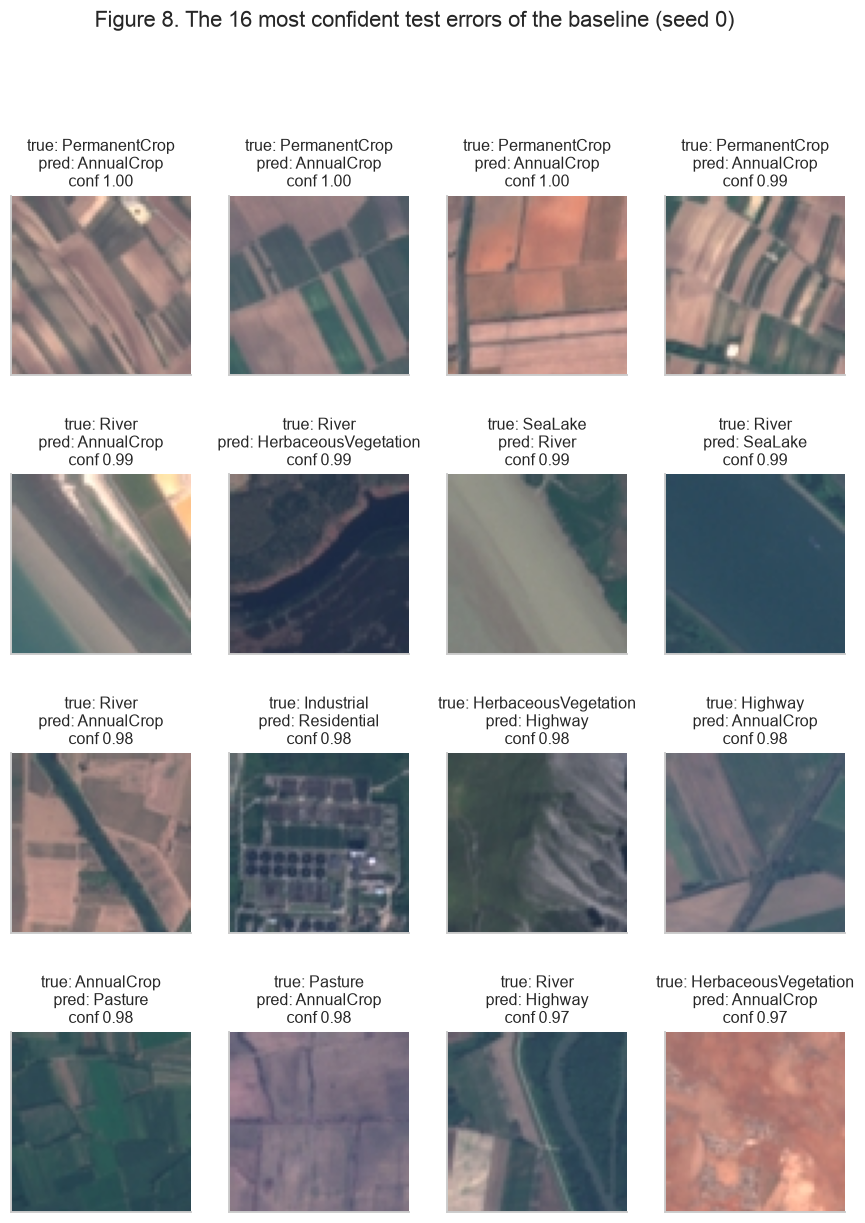

In [22]:
y_true_te = labels[te_idx]
p0 = probs[("baseline", 0)]
pred0, conf0 = p0.argmax(1), p0.max(1)
wrong = np.where(pred0 != y_true_te)[0]
print(f"Baseline seed 0: {len(wrong)} of {len(te_idx)} test images misclassified ({100 * len(wrong) / len(te_idx):.2f} %)")

# Gallery: the 16 most confident mistakes
order = wrong[np.argsort(-conf0[wrong])][:16]
fig, axes = plt.subplots(4, 4, figsize=(10, 12), gridspec_kw={"hspace": 0.55, "wspace": 0.1})
for ax, i in zip(axes.ravel(), order):
    ax.imshow(X[te_idx[i]]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"true: {CLASSES[y_true_te[i]]}\npred: {CLASSES[pred0[i]]}\nconf {conf0[i]:.2f}", fontsize=10.5)
fig.suptitle("Figure 8. The 16 most confident test errors of the baseline (seed 0)", y=1.02)
savefig(fig, "fig8_error_gallery")
plt.show()

,mean conf. when correct,mean conf. when wrong,errors,errors with conf > 0.9
config,,,,
baseline,0.9756,0.7200,162,34
dropout,0.9784,0.7375,147,30


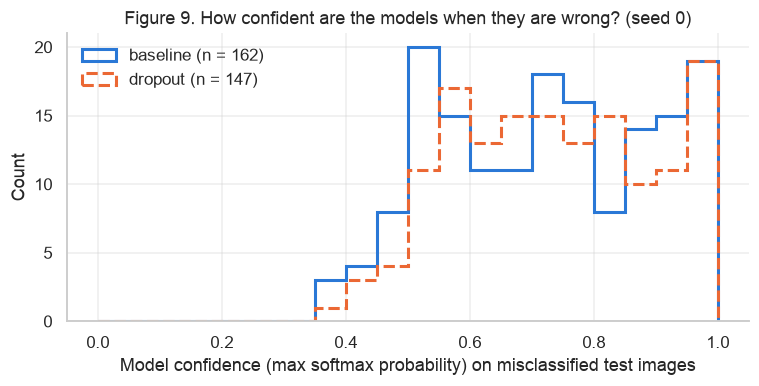

In [23]:
# Confidence on correct vs wrong predictions, both configurations (seed 0)
conf_rows = []
for cfg in ["baseline", "dropout"]:
    p = probs[(cfg, 0)]
    correct = p.argmax(1) == y_true_te
    conf_rows.append({"config": cfg,
                      "mean conf. when correct": p.max(1)[correct].mean(),
                      "mean conf. when wrong": p.max(1)[~correct].mean(),
                      "errors": int((~correct).sum()),
                      "errors with conf > 0.9": int(((p.max(1) > 0.9) & ~correct).sum())})
conf_df = pd.DataFrame(conf_rows).set_index("config")
conf_df.to_csv(MET_DIR / "confidence_seed0.csv")
display(conf_df.round(4))

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 21)
for cfg in ["baseline", "dropout"]:
    p = probs[(cfg, 0)]
    wrong_conf = p.max(1)[p.argmax(1) != y_true_te]
    ax.hist(wrong_conf, bins=bins, histtype="step", lw=2, ls=STYLES[cfg], color=COLORS[cfg], label=f"{cfg} (n = {len(wrong_conf)})")
ax.set_xlabel("Model confidence (max softmax probability) on misclassified test images")
ax.set_ylabel("Count")
ax.legend(frameon=False)
ax.set_title("Figure 9. How confident are the models when they are wrong? (seed 0)")
savefig(fig, "fig9_error_confidence")
plt.show()

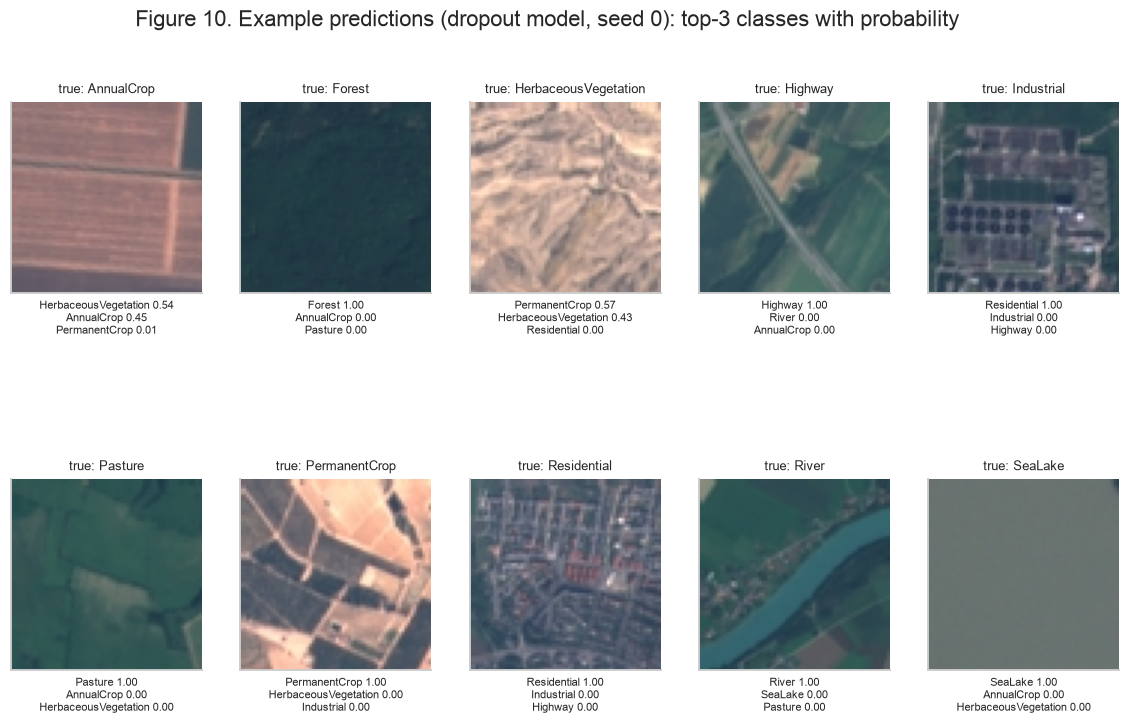

In [24]:
# Example predictions: one random test image per class with the dropout model's top-3 classes (seed 0)
rng = np.random.default_rng(1)
pd0 = probs[("dropout", 0)]
fig, axes = plt.subplots(2, 5, figsize=(13, 7.2), gridspec_kw={"hspace": 0.62})
for c, ax in enumerate(axes.ravel()):
    i = rng.choice(np.where(y_true_te == c)[0])
    top3 = np.argsort(-pd0[i])[:3]
    ax.imshow(X[te_idx[i]]); ax.set_xticks([]); ax.set_yticks([])
    txt = "\n".join(f"{CLASSES[k]} {pd0[i, k]:.2f}" for k in top3)
    ax.set_title(f"true: {CLASSES[c]}", fontsize=8.5)
    ax.set_xlabel(txt, fontsize=7.5)
fig.suptitle("Figure 10. Example predictions (dropout model, seed 0): top-3 classes with probability", y=0.97)
savefig(fig, "fig10_example_predictions")
plt.show()

## 10. Notebook summary

This notebook trained a CNN to classify 27,000 EuroSAT Sentinel-2 RGB images into 10 land-use classes, using a stratified 70/15/15 split with training-set-only normalisation. The baseline (three Conv-BN-ReLU blocks with global average pooling, 323,050 parameters, Adam at 1e-3 for 25 epochs) reached **96.4 % ± 0.5 test accuracy (macro-F1 0.963)** over three seeds, and the experiment, which changed only one setting (dropout p = 0.5 in the classifier head), reached **96.2 % ± 0.3 (macro-F1 0.961)**. The mean paired difference of −0.19 percentage points is smaller than the seed-to-seed spread (dropout won on 2 of 3 seeds), so dropout neither helped nor hurt measurably. The mean train–test gap was slightly smaller (1.4 vs. 1.8 points), but its sign flipped for one seed, so this is also within noise. Both models struggle with the same visually similar classes, mainly PermanentCrop vs. HerbaceousVegetation/AnnualCrop and River vs. Highway, and about one in five errors is made with over 90 % confidence (34 of 162 for baseline seed 0). The unexpected finding was that the baseline barely overfit within 25 epochs, which left little for dropout to fix and makes the experiment a useful negative result rather than a win.